In [ ]:
import os, sys

if "google.colab" in sys.modules:
    !apt-get install -y -qq openjdk-17-jdk-headless > /dev/null
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    !pip install -q pyspark pymongo mongomock plotly seaborn "streamlit>=1.50"
    !java -version

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [ ]:
if not os.path.exists("datasets.csv"):
    from google.colab import files
    files.upload()
print("datasets.csv listo:", os.path.exists("datasets.csv"))

Saving datasets.csv to datasets.csv
datasets.csv listo: True


In [ ]:
%%writefile limpieza.py
"""Limpieza compartida por el notebook y el dashboard (una sola fuente de verdad)."""
import numpy as np
import pandas as pd

ANIO_ACTUAL = 2026
CENTINELAS = ["-", "PARSE_ERROR", ""]
COLS_BOOL = ["red", "host", "etiquetado", "tiene_windows", "tiene_linux"]


def leer_crudo(ruta="datasets.csv"):
    return pd.read_csv(ruta, sep=";", dtype=str, keep_default_na=False)


def _etiqueta(texto, existe):
    if existe == "No":
        return "No aplica"
    t = texto.lower()
    if t.startswith("no"):
        return "No"
    if t.startswith("yes") or "ground truth" in t or "flows are labeled" in t:
        return "Sí"
    return "Sin dato"


def _benigno(texto):
    t = texto.lower()
    if "synthetic" in t and "real humans" in t:
        return "Mixto"
    if t.startswith("real"):
        return "Real"
    if "synthetic" in t:
        return "Sintético"
    if t == "none":
        return "Ninguno"
    if t == "n/a":
        return "No aplica"
    if t.startswith("present"):
        return "No especificado"
    return "Sin dato"


def limpiar(raw):
    df = raw.copy()
    df.columns = [c.strip() for c in df.columns]
    df = df.apply(lambda s: s.str.strip()).drop_duplicates()
    o = pd.DataFrame({"nombre": df["Name"]})
    o["anio_inicio"] = df["Start Year"].astype(int)
    o["anio_fin"] = df["End Year"].astype(int)
    o["epoca"] = pd.cut(o.anio_fin, [1990, 2009, 2015, 2020, 2026],
                        labels=["1998-2009", "2010-2015", "2016-2020", "2021-2025"]).astype(str)
    o["red"] = df["Network Data"].eq("Yes")
    o["host"] = df["Host Data"].eq("Yes")
    o["tipo_datos"] = np.select([o.red & o.host, o.red, o.host], ["Red + Host", "Solo red", "Solo host"], "Ninguno")
    o["entorno"] = df["Setting"].replace({"Undisclosed": "No declarado"})
    o["so"] = df["OS Type"].replace({"Undisclosed": "No declarado"})
    o["tiene_windows"] = df["OS Type"].str.contains("Windows")
    o["tiene_linux"] = df["OS Type"].str.contains("Linux")
    o["etiq_red"] = [_etiqueta(t, e) for t, e in zip(df["Network Data Labeled"], df["Network Data"])]
    o["etiq_host"] = [_etiqueta(t, e) for t, e in zip(df["Host Data Labeled"], df["Host Data"])]
    o["etiquetado"] = (o.etiq_red == "Sí") | (o.etiq_host == "Sí")
    o["ataques"] = df["Attack Categories"].replace({"": "No especificado", "-": "No especificado", "n/a": "No aplica"})
    o["trafico_benigno"] = df["Benign Activity"].map(_benigno)
    for src, dst in [("Packed Size in MB", "empaquetado_mb"), ("Unpacked Size in MB", "descomprimido_mb"),
                     ("Times Recently Cited", "citas")]:
        o[dst] = pd.to_numeric(df[src].replace(CENTINELAS, np.nan), errors="coerce")
    o[["empaquetado_mb", "descomprimido_mb"]] = o[["empaquetado_mb", "descomprimido_mb"]].round(1)
    o["tamano_gb"] = (o.descomprimido_mb.fillna(o.empaquetado_mb) / 1024).round(4)
    o["categoria_tamano"] = pd.cut(o.tamano_gb, [0, 1, 10, 100, 1024, np.inf],
                                   labels=["<1 GB", "1-10 GB", "10-100 GB", "100 GB-1 TB", ">1 TB"]).astype(object).fillna("Sin dato")
    o["antiguedad"] = ANIO_ACTUAL - o.anio_fin
    return o.reset_index(drop=True)


def para_csv(df):
    """Booleanos como 0/1 para que Spark los infiera como enteros sin ambigüedad."""
    return df.astype({c: int for c in COLS_BOOL})

Writing limpieza.py


In [ ]:
%%writefile app.py
from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

from limpieza import leer_crudo, limpiar

st.set_page_config(page_title="Datasets de ciberseguridad", layout="wide")
SIN_LIMITE = 10_000_000


@st.cache_data
def cargar():
    return limpiar(leer_crudo(Path(__file__).parent / "datasets.csv"))


df = cargar()

st.title("¿Qué dataset de ciberseguridad me conviene?")
st.caption("Catálogo de 61 datasets para detección de intrusiones. Filtra según tu caso de uso.")

st.sidebar.header("Filtros")
a_min, a_max = int(df.anio_fin.min()), int(df.anio_fin.max())
anios = st.sidebar.slider("Año de publicación", a_min, a_max, (2015, a_max))
tipos = st.sidebar.multiselect("Tipo de datos", sorted(df.tipo_datos.unique()), default=sorted(df.tipo_datos.unique()))
entornos = st.sidebar.multiselect("Entorno", sorted(df.entorno.unique()), default=sorted(df.entorno.unique()))
solo_etiq = st.sidebar.checkbox("Solo datasets etiquetados")
max_gb = st.sidebar.select_slider(
    "Tamaño máximo", [1, 10, 50, 100, 1024, SIN_LIMITE], value=SIN_LIMITE,
    format_func=lambda v: "Sin límite" if v == SIN_LIMITE else (f"{v} GB" if v < 1024 else "1 TB"))

f = df[df.anio_fin.between(*anios) & df.tipo_datos.isin(tipos) & df.entorno.isin(entornos)]
if solo_etiq:
    f = f[f.etiquetado]
f = f[(f.tamano_gb <= max_gb) | (f.tamano_gb.isna() & (max_gb == SIN_LIMITE))]

if f.empty:
    st.warning("Ningún dataset cumple los filtros. Relaja alguno.")
    st.stop()


k1, k2, k3, k4 = st.columns(4)
k1.metric("Datasets", len(f))
k2.metric("Con red + host", f"{(f.tipo_datos == 'Red + Host').mean():.0%}")
k3.metric("Etiquetados", f"{f.etiquetado.mean():.0%}")
k4.metric("Tamaño mediano", "s/d" if f.tamano_gb.isna().all() else f"{f.tamano_gb.median():.1f} GB")


c1, c2 = st.columns(2)
c1.plotly_chart(px.histogram(f, x="anio_fin", color="tipo_datos", title="Datasets por año y tipo de datos",
                             labels={"anio_fin": "Año", "count": "Datasets"}), width="stretch")
cit = f[f.citas > 0]
c2.plotly_chart(px.scatter(cit, x="anio_fin", y="citas", color="tipo_datos", hover_name="nombre", log_y=True,
                           title="Citas recientes vs. año (escala log)", labels={"anio_fin": "Año"}),
                width="stretch")
c3, c4 = st.columns(2)
c3.plotly_chart(px.bar(f.groupby(["entorno", "tipo_datos"]).size().reset_index(name="n"), x="entorno", y="n",
                       color="tipo_datos", title="Entornos cubiertos"), width="stretch")
c4.plotly_chart(px.box(f.dropna(subset=["tamano_gb"]), x="tipo_datos", y="tamano_gb", points="all",
                       hover_name="nombre", log_y=True, title="Tamaño en disco (GB, escala log)"),
                width="stretch")
c5, _ = st.columns(2)
c5.plotly_chart(px.pie(f, names="trafico_benigno", hole=0.45, title="Origen del tráfico benigno"),
                width="stretch")

st.subheader("Datasets que cumplen tus filtros")
tabla = f[["nombre", "anio_fin", "tipo_datos", "entorno", "so", "etiquetado", "tamano_gb", "citas", "ataques"]]
tabla = tabla.sort_values("citas", ascending=False, na_position="last")
st.dataframe(tabla, width="stretch", hide_index=True)
st.download_button("Descargar selección (CSV)", tabla.to_csv(index=False).encode("utf-8"), "seleccion.csv")

Writing app.py


In [ ]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from limpieza import leer_crudo, limpiar, para_csv, CENTINELAS

raw = leer_crudo("datasets.csv")
print("Filas, columnas:", raw.shape)
raw.head(3)

Filas, columnas: (61, 16)


,Name,Network Data,Host Data,Start Year,End Year,Setting,OS Type,Network Data Source,Network Data Labeled,Host Data Source,Host Data Labeled,Attack Categories,Benign Activity,Packed Size in MB,Unpacked Size in MB,Times Recently Cited
0,CasinoLimit,Yes,Yes,2025,2025,Enterprise IT,Linux,NetFlows,Yes,"Syslog, auditd",Yes,Most ATT&CK tactics,PARSE_ERROR,3600.0,54400.0,0
1,DEDALE,Yes,Yes,2025,2025,Enterprise IT,"Windows, Linux","NetFlows, pcaps",Yes,"Windows events, Linux events",Yes,Various ATT&CK tactics,PARSE_ERROR,2960000.0,8199999.999999999,0
2,AIT Alert Dataset,Yes,Yes,2023,2023,Enterprise IT,Linux,"Suricata, Wazuh and AMiner alerts",Yes,Wazuh and AMiner alerts,Yes,"Reconnaissance, Privilege Escalation, Data Exf...","Synthetic, models complex behavior",96.0,2900.0,22


In [ ]:
print("Tipos de datos (todo es texto):")
print(raw.dtypes.value_counts(), "\n")
print("Duplicados exactos:", raw.duplicated().sum(), "| nombres repetidos:", raw["Name"].str.strip().duplicated().sum())
print("\nFaltantes codificados como '-', 'PARSE_ERROR' o vacío:")
print(raw.apply(lambda s: s.isin(CENTINELAS).sum())[lambda s: s > 0].sort_values(ascending=False))
print("\nCitas más repetidas:\n", raw["Times Recently Cited"].value_counts().head(3))

Tipos de datos (todo es texto):
object    16
Name: count, dtype: int64 

Duplicados exactos: 0 | nombres repetidos: 0

Faltantes codificados como '-', 'PARSE_ERROR' o vacío:
Host Data Source        27
Host Data Labeled       27
Unpacked Size in MB     22
Packed Size in MB       15
Network Data Source     13
Benign Activity         13
Network Data Labeled    13
Times Recently Cited    13
Attack Categories        1
dtype: int64

Citas más repetidas:
 Times Recently Cited
-     13
23     3
22     2
Name: count, dtype: int64


In [ ]:
df = limpiar(raw)
para_csv(df).to_csv("datasets_limpio.csv", index=False)

assert len(df) == 61 and (df.anio_inicio <= df.anio_fin).all()
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
df.head()

(61, 22)
empaquetado_mb      15
descomprimido_mb    22
citas               13
tamano_gb            5
dtype: int64


,nombre,anio_inicio,anio_fin,epoca,red,host,tipo_datos,entorno,so,tiene_windows,...,etiq_host,etiquetado,ataques,trafico_benigno,empaquetado_mb,descomprimido_mb,citas,tamano_gb,categoria_tamano,antiguedad
0,CasinoLimit,2025,2025,2021-2025,True,True,Red + Host,Enterprise IT,Linux,False,...,Sí,True,Most ATT&CK tactics,Sin dato,3600.0,54400.0,0.0,53.1250,10-100 GB,1
1,DEDALE,2025,2025,2021-2025,True,True,Red + Host,Enterprise IT,"Windows, Linux",True,...,Sí,True,Various ATT&CK tactics,Sin dato,2960000.0,8200000.0,0.0,8007.8125,>1 TB,1
2,AIT Alert Dataset,2023,2023,2021-2025,True,True,Red + Host,Enterprise IT,Linux,False,...,Sí,True,"Reconnaissance, Privilege Escalation, Data Exf...",Sintético,96.0,2900.0,22.0,2.8320,1-10 GB,3
3,FLNET2023,2023,2023,2021-2025,True,False,Solo red,ISP-like,No declarado,False,...,No aplica,True,"DDOS & DOS, Infiltration, Web-based (SQLi, XSS...",Sin dato,NaN,176000.0,14.0,171.8750,100 GB-1 TB,3
4,OTFR Security Datasets - LSASS Campaign,2023,2023,2021-2025,True,True,Red + Host,Single OS,Windows,True,...,No,False,"Resource Development, Execution, Discovery, Pr...",Ninguno,423.0,1000.0,NaN,0.9766,<1 GB,3


In [ ]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.appName("catalogo-ciber").master("local[*]")
         .config("spark.sql.shuffle.partitions", "4").getOrCreate())
sdf = spark.read.csv("datasets_limpio.csv", header=True, inferSchema=True)

n = sdf.count()
assert n == len(df)
print("Filas leídas por Spark:", n)
sdf.printSchema()

Filas leídas por Spark: 61
root
 |-- nombre: string (nullable = true)
 |-- anio_inicio: integer (nullable = true)
 |-- anio_fin: integer (nullable = true)
 |-- epoca: string (nullable = true)
 |-- red: integer (nullable = true)
 |-- host: integer (nullable = true)
 |-- tipo_datos: string (nullable = true)
 |-- entorno: string (nullable = true)
 |-- so: string (nullable = true)
 |-- tiene_windows: integer (nullable = true)
 |-- tiene_linux: integer (nullable = true)
 |-- etiq_red: string (nullable = true)
 |-- etiq_host: string (nullable = true)
 |-- etiquetado: integer (nullable = true)
 |-- ataques: string (nullable = true)
 |-- trafico_benigno: string (nullable = true)
 |-- empaquetado_mb: double (nullable = true)
 |-- descomprimido_mb: double (nullable = true)
 |-- citas: double (nullable = true)
 |-- tamano_gb: double (nullable = true)
 |-- categoria_tamano: string (nullable = true)
 |-- antiguedad: integer (nullable = true)



In [ ]:
modernos = sdf.filter((F.col("anio_fin") >= 2019) & (F.col("tipo_datos") == "Red + Host"))
n_mod = modernos.count()
assert n_mod == len(df[(df.anio_fin >= 2019) & (df.tipo_datos == "Red + Host")])
print("Datasets 2019+ con red + host:", n_mod)
modernos.select("nombre", "anio_fin", "tamano_gb", "citas").orderBy(F.desc("citas")).show(truncate=False)

Datasets 2019+ con red + host: 13
+---------------------------------------+--------+---------+-----+
|nombre                                 |anio_fin|tamano_gb|citas|
+---------------------------------------+--------+---------+-----+
|DAPT 2020                              |2020    |0.4492   |86.0 |
|Unraveled                              |2021    |21.4844  |49.0 |
|AIT Log Dataset                        |2022    |201.1719 |44.0 |
|SOCBED Example Dataset                 |2021    |1.2695   |30.0 |
|AIT Alert Dataset                      |2023    |2.832    |22.0 |
|PWNJUTSU                               |2022    |80.0781  |11.0 |
|CasinoLimit                            |2025    |53.125   |0.0  |
|DEDALE                                 |2025    |8007.8125|0.0  |
|OTFR Security Datasets - LSASS Campaign|2023    |0.9766   |NULL |
|OTFR Security Datasets - Atomic        |2022    |0.1221   |NULL |
|OTFR Security Datasets - Log4Shell     |2021    |0.001    |NULL |
|OpTC                       

In [ ]:
por_entorno = (sdf.groupBy("entorno")
               .agg(F.count("*").alias("n"), F.round(F.avg("citas"), 1).alias("citas_prom"),
                    F.round(F.expr("percentile_approx(tamano_gb, 0.5)"), 1).alias("mediana_gb"))
               .orderBy(F.desc("n")))
assert por_entorno.agg(F.sum("n")).first()[0] == n
por_entorno.show(truncate=False)

+-------------+---+----------+----------+
|entorno      |n  |citas_prom|mediana_gb|
+-------------+---+----------+----------+
|Enterprise IT|34 |384.9     |11.7      |
|Single OS    |11 |44.9      |0.5       |
|Military IT  |5  |668.0     |4.9       |
|Miscellaneous|5  |107.6     |19.5      |
|No declarado |3  |2867.0    |97.7      |
|Subsystem    |1  |7.0       |14.6      |
|ISP-like     |1  |14.0      |171.9     |
|Home IT      |1  |297.0     |11.4      |
+-------------+---+----------+----------+



In [ ]:
sdf.createOrReplaceTempView("catalogo")
por_epoca = spark.sql('''
    SELECT epoca, COUNT(*) AS n, SUM(etiquetado) AS etiquetados,
           ROUND(100 * SUM(etiquetado) / COUNT(*), 1) AS pct_etiquetado,
           SUM(citas) AS citas_totales, MAX(citas) AS citas_max
    FROM catalogo GROUP BY epoca ORDER BY epoca
''')
assert por_epoca.agg(F.sum("n")).first()[0] == n
por_epoca.show()

+---------+---+-----------+--------------+-------------+---------+
|    epoca|  n|etiquetados|pct_etiquetado|citas_totales|citas_max|
+---------+---+-----------+--------------+-------------+---------+
|1998-2009|  6|          6|         100.0|       2722.0|   2483.0|
|2010-2015| 17|         13|          76.5|       5054.0|   2867.0|
|2016-2020| 19|         14|          73.7|       9105.0|   3829.0|
|2021-2025| 19|         14|          73.7|        605.0|    341.0|
+---------+---+-----------+--------------+-------------+---------+



In [ ]:
perfiles = spark.createDataFrame(
    [("Red + Host", "Correlación de eventos (SIEM/XDR)"), ("Solo red", "IDS de red / NetFlow"),
     ("Solo host", "EDR / análisis de logs de host")], ["tipo_datos", "uso_tipico"])
unido = sdf.join(perfiles, "tipo_datos", "left")
assert unido.count() == n
assert unido.filter(F.col("uso_tipico").isNull()).count() == 0
unido.groupBy("uso_tipico").count().show(truncate=False)

+---------------------------------+-----+
|uso_tipico                       |count|
+---------------------------------+-----+
|IDS de red / NetFlow             |28   |
|Correlación de eventos (SIEM/XDR)|21   |
|EDR / análisis de logs de host   |12   |
+---------------------------------+-----+



In [ ]:
from pymongo import MongoClient
try:
    cliente = MongoClient(os.getenv("MONGO_URI", "mongodb://localhost:27017"), serverSelectionTimeoutMS=2000)
    cliente.admin.command("ping"); motor = "MongoDB real"
except Exception:
    import mongomock
    cliente = mongomock.MongoClient(); motor = "mongomock (sin servidor)"
print("Motor:", motor)

col = cliente["ciberseguridad"]["datasets"]
col.delete_many({})
col.insert_many(json.loads(df.to_json(orient="records")))
assert col.count_documents({}) == len(df)
print("Documentos:", col.count_documents({}))

Motor: mongomock (sin servidor)
Documentos: 61


In [ ]:
perfil = {"$and": [{"anio_fin": {"$gte": 2019}}, {"red": True}, {"host": True},
                   {"etiquetado": True}, {"tamano_gb": {"$lte": 50}}]}
res = list(col.find(perfil, {"_id": 0, "nombre": 1, "anio_fin": 1, "tamano_gb": 1, "citas": 1, "ataques": 1}).sort("citas", -1))
esperado = df[(df.anio_fin >= 2019) & df.red & df.host & df.etiquetado & (df.tamano_gb <= 50)]
assert len(res) == len(esperado)
print("Datasets que cumplen el perfil:", len(res))
pd.DataFrame(res)

Datasets que cumplen el perfil: 4


,nombre,anio_fin,ataques,citas,tamano_gb
0,DAPT 2020,2020,"Reconnaissance, Persistence, Lateral Movement,...",86.0,0.4492
1,Unraveled,2021,"Reconnaissance, Persistence, Lateral Movement,...",49.0,21.4844
2,AIT Alert Dataset,2023,"Reconnaissance, Privilege Escalation, Data Exf...",22.0,2.8320
3,OTFR Security Datasets - Atomic,2022,Most of MITRE's Att&ck matrix,NaN,0.1221


In [ ]:
n_win = col.count_documents({"entorno": {"$in": ["Enterprise IT", "Military IT"]}, "so": {"$regex": "Windows"}})
assert n_win == len(df[df.entorno.isin(["Enterprise IT", "Military IT"]) & df.so.str.contains("Windows")])
print("Corporativos/militares con Windows:", n_win)

pipeline = [{"$match": {"citas": {"$ne": None}, "tamano_gb": {"$ne": None}}},
            {"$group": {"_id": "$epoca", "datasets": {"$sum": 1}, "citas_totales": {"$sum": "$citas"},
                        "citas_max": {"$max": "$citas"}, "tamano_prom_gb": {"$avg": "$tamano_gb"}}},
            {"$sort": {"_id": 1}}]
pd.DataFrame(list(col.aggregate(pipeline))).rename(columns={"_id": "epoca"}).round(1)

Corporativos/militares con Windows: 18


,datasets,citas_totales,citas_max,tamano_prom_gb,epoca
0,5,2722.0,2483.0,6.3,1998-2009
1,14,4983.0,2867.0,69.7,2010-2015
2,12,9031.0,3829.0,54.0,2016-2020
3,13,582.0,341.0,674.8,2021-2025


In [ ]:
cit = df[df.citas > 0]
fig = px.scatter(cit, x="anio_fin", y="citas", color="tipo_datos", hover_name="nombre", log_y=True,
                 labels={"anio_fin": "Año", "citas": "Citas recientes (log)"},
                 title="Los datasets más citados son de hace casi una década")
fig.show()
print("Datasets con 100+ citas:", (df.citas >= 100).sum(), "| de ellos, de 2017 o antes:", ((df.citas >= 100) & (df.anio_fin <= 2017)).sum())

Datasets con 100+ citas: 15 | de ellos, de 2017 o antes: 12


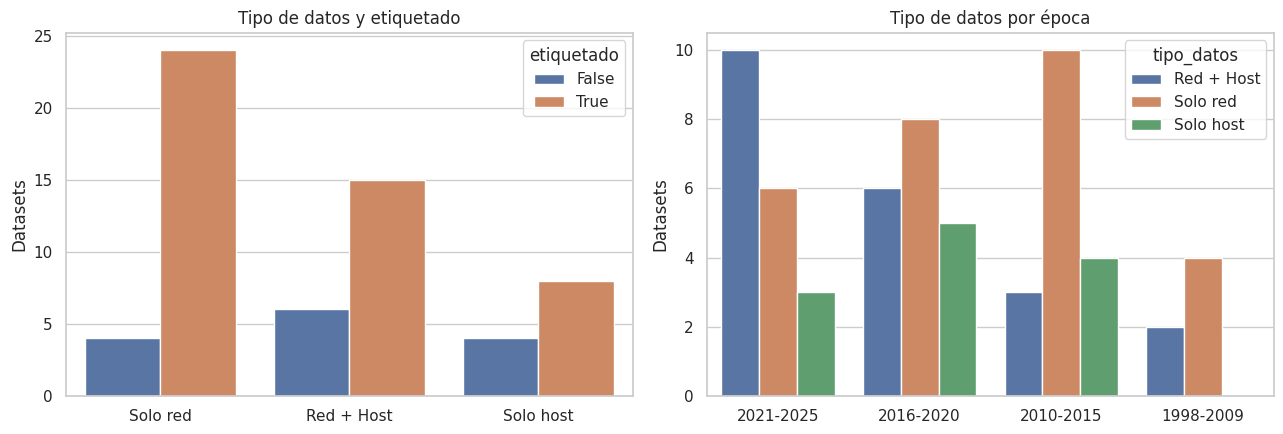

In [ ]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="tipo_datos", order=["Solo red", "Red + Host", "Solo host"], hue="etiquetado", ax=ax[0])
ax[0].set(title="Tipo de datos y etiquetado", xlabel="", ylabel="Datasets")
sns.countplot(data=df, x="epoca", hue="tipo_datos", ax=ax[1])
ax[1].set(title="Tipo de datos por época", xlabel="", ylabel="Datasets")
plt.tight_layout(); plt.show()

In [ ]:
px.bar(df.groupby(["entorno", "so"]).size().reset_index(name="n"), x="entorno", y="n", color="so",
       title="Datasets por entorno y sistema operativo", labels={"n": "Datasets"}).show()

Tamaño en disco (n=56): Q1=1.2 GB, mediana=10.9 GB, Q3=49.9 GB, máx=8008 GB


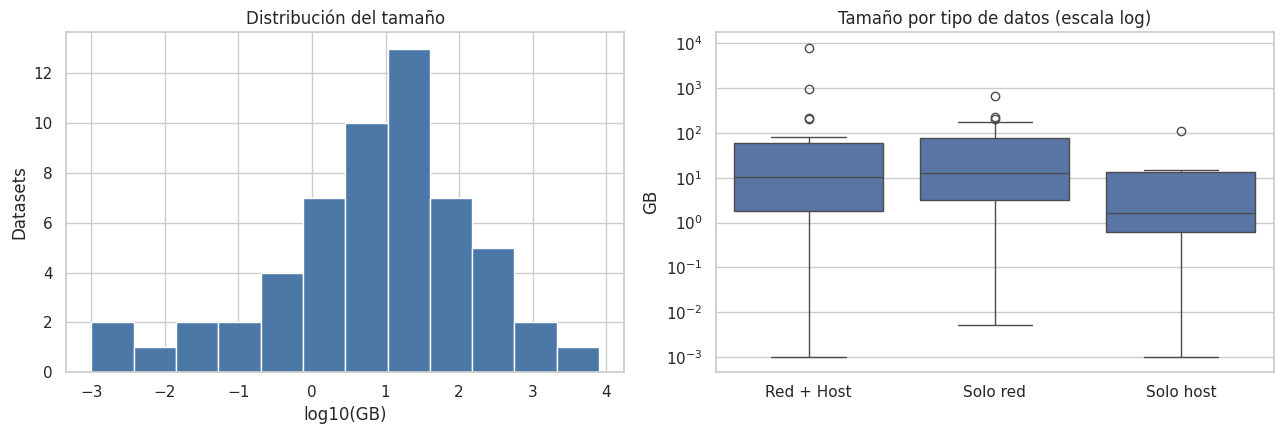

categoria_tamano
10-100 GB      20
<1 GB          14
1-10 GB        13
100 GB-1 TB     8
Sin dato        5
>1 TB           1
Name: count, dtype: int64


In [ ]:
gb = df.tamano_gb.dropna().to_numpy()
q1, med, q3 = np.percentile(gb, [25, 50, 75])
print(f"Tamaño en disco (n={len(gb)}): Q1={q1:.1f} GB, mediana={med:.1f} GB, Q3={q3:.1f} GB, máx={gb.max():.0f} GB")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(np.log10(gb[gb > 0]), bins=12, color="#4c78a8")
ax[0].set(title="Distribución del tamaño", xlabel="log10(GB)", ylabel="Datasets")
sns.boxplot(data=df.dropna(subset=["tamano_gb"]), x="tipo_datos", y="tamano_gb", ax=ax[1])
ax[1].set(yscale="log", title="Tamaño por tipo de datos (escala log)", xlabel="", ylabel="GB")
plt.tight_layout(); plt.show()
print(df.categoria_tamano.value_counts())

In [ ]:
pd.DataFrame(res)[["nombre", "anio_fin", "tamano_gb", "citas", "ataques"]]

,nombre,anio_fin,tamano_gb,citas,ataques
0,DAPT 2020,2020,0.4492,86.0,"Reconnaissance, Persistence, Lateral Movement,..."
1,Unraveled,2021,21.4844,49.0,"Reconnaissance, Persistence, Lateral Movement,..."
2,AIT Alert Dataset,2023,2.8320,22.0,"Reconnaissance, Privilege Escalation, Data Exf..."
3,OTFR Security Datasets - Atomic,2022,0.1221,NaN,Most of MITRE's Att&ck matrix


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false &>/content/logs.txt &
!sleep 6
!./cloudflared tunnel --url http://localhost:8501 --no-autoupdate

2026-11-10T17:24:27Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-10T17:24:27Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-10T17:24:33Z INF +--------------------------------------------------------------------------------------------+
2026-11-10T17:24:33Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-10T17:24:33Z INF |  https://revisions-packard-jackets-injuries.trycloudfl